# P03: our first CNN

The dense baseline (P02) flattens each image and ignores which pixels are neighbours. A **convolutional network (CNN)**
keeps the image shape: small filters slide over the image and reuse the same weights at every position, so a pattern
(an edge, a texture) is recognised wherever it appears. Pooling shrinks the image between layers, so later layers see
larger areas.

Here the CNN is **described by a config** (the number of convolution blocks and their filters, batch norm, dropout...).
One call to `run_experiment` then does everything with the same data, the same split and the same training loop as the
baseline: load the data, build the model, train it (best epoch kept on validation), repeat with other seeds, make the
confusion matrix, and record the run in `results/`.

**The test set (museum B) is not used here** (ADR 0003).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import torch

from deep_learning_project_waerniers_lamy.vision.utils import (
    add_test_score, build_cnn, load_data, run_experiment, summary, to_images)

# The model is described here. To try another model, change this dict and run again.
CONFIG = {
    "model": "cnn",
    "image_size": 64,  # images are shrunk to 64 x 64 pixels (the dense baseline used 32)
    "conv_channels": [16, 32, 64],  # 3 convolution blocks, with 16, 32 and 64 filters
    "kernel_size": 3,  # filters of 3 x 3 pixels
    "batch_norm": False,
    "dropout": 0.0,
    "epochs": 30,
    "lr": 1e-3,
    "batch_size": 64,
    "weight_decay": 0.0,
    "seed": 0,
}
NAME = "cnn_first"

## 1. The model described by the config

Each block is a convolution, a ReLU and a max pooling that halves the image. After the last block, each feature map is
averaged into a single number, so the final layer only has 64 inputs. That keeps the network small: the dense baseline
has 393,989 weights for 1,920 training images.

We build it once just to look at it: how the image shape changes layer by layer, and how many weights it has.

In [2]:
model = build_cnn(CONFIG)

x = torch.zeros(1, 3, CONFIG["image_size"], CONFIG["image_size"])  # one blank image, to follow its shape
for layer in model:
    x = layer(x)
    print(f"{layer.__class__.__name__:18s} -> {tuple(x.shape)}")

print("\nparameters:", sum(p.numel() for p in model.parameters()), "| dense baseline: 393989")

Conv2d             -> (1, 16, 64, 64)
ReLU               -> (1, 16, 64, 64)
MaxPool2d          -> (1, 16, 32, 32)
Conv2d             -> (1, 32, 32, 32)
ReLU               -> (1, 32, 32, 32)
MaxPool2d          -> (1, 32, 16, 16)
Conv2d             -> (1, 64, 16, 16)
ReLU               -> (1, 64, 16, 16)
MaxPool2d          -> (1, 64, 8, 8)
AdaptiveAvgPool2d  -> (1, 64, 1, 1)
Flatten            -> (1, 64)
Dropout            -> (1, 64)
Linear             -> (1, 5)

parameters: 23909 | dense baseline: 393989


## 2. Run the experiment

`run_experiment` prints the starting loss (it should be near ln 5 = 1.61 with random weights), trains the main run with
the config's seed, then trains 4 more seeds quietly to see how much the result moves. About 3.5 minutes per run on a CPU.

In [3]:
outcome = run_experiment(NAME, CONFIG, seeds=5)

23909 parameters | before training: loss 1.609 (ln 5 = 1.609), accuracy 19.5%
epoch   1 | train loss 1.506 acc 0.322 | val loss 1.555 acc 0.265
epoch   5 | train loss 1.343 acc 0.415 | val loss 1.413 acc 0.379
epoch  10 | train loss 1.200 acc 0.503 | val loss 1.268 acc 0.471
epoch  15 | train loss 1.119 acc 0.569 | val loss 1.183 acc 0.481
epoch  20 | train loss 1.081 acc 0.584 | val loss 1.160 acc 0.504
epoch  25 | train loss 1.072 acc 0.566 | val loss 1.155 acc 0.490
epoch  30 | train loss 1.041 acc 0.597 | val loss 1.145 acc 0.537

best validation accuracy 53.8% at epoch 30 (129 s)
seed 1 (1 of 4 more): training, about 129 s...
   best validation accuracy 54.8% at epoch 28
seed 2 (2 of 4 more): training, about 129 s...
   best validation accuracy 53.5% at epoch 30
seed 3 (3 of 4 more): training, about 129 s...
   best validation accuracy 53.1% at epoch 30
seed 4 (4 of 4 more): training, about 129 s...
   best validation accuracy 52.7% at epoch 30
saved results/cnn_first_2026-10-21_1

## 3. Learning curves

If the train curve keeps improving while the validation curve stalls or gets worse, the model is memorising the training
images (overfitting).

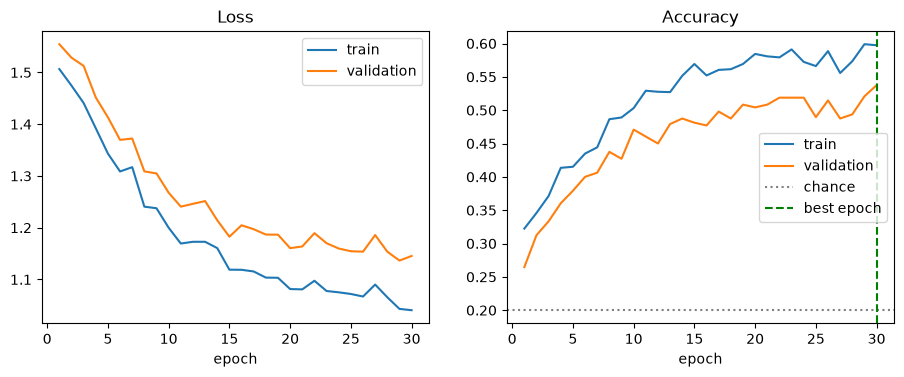

In [4]:
history = outcome["result"]["history"]
epochs = range(1, len(history["train_loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(epochs, history["train_loss"], label="train")
ax1.plot(epochs, history["val_loss"], label="validation")
ax1.set_title("Loss")
ax1.set_xlabel("epoch")
ax1.legend()

ax2.plot(epochs, history["train_acc"], label="train")
ax2.plot(epochs, history["val_acc"], label="validation")
ax2.axhline(0.2, color="grey", linestyle=":", label="chance")
ax2.axvline(outcome["result"]["best_epoch"], color="green", linestyle="--", label="best epoch")
ax2.set_title("Accuracy")
ax2.set_xlabel("epoch")
ax2.legend()
plt.show()

## 4. Where does it go wrong on validation?

In [5]:
confusion = outcome["confusion"]
classes = list(confusion.index)
per_class = pd.Series({c: confusion.loc[c, c] / confusion.loc[c].sum() for c in classes}, name="accuracy").round(2)
display(confusion)
display(per_class.to_frame())

predicted,cityscape,landscape,portrait,religious_painting,still_life
true genre,,,,,
cityscape,53,23,5,10,5
landscape,22,60,1,3,10
portrait,9,2,72,8,5
religious_painting,16,2,36,33,9
still_life,15,9,27,5,40


,accuracy
cityscape,0.55
landscape,0.62
portrait,0.75
religious_painting,0.34
still_life,0.42


## 5. Compared with the dense baseline

Same data, same split, same training loop. The table comes from `results/experiments.csv`, best validation score first.

In [6]:
summary()[["name", "model", "image_size", "n_params", "best_epoch", "best_val_acc", "val_acc_mean", "val_acc_std"]]

,name,model,image_size,n_params,best_epoch,best_val_acc,val_acc_mean,val_acc_std
2,cnn_first,cnn,64,23909,30,0.5375,0.5358,0.0079
0,dense_baseline,dense,32,393989,8,0.3854,0.3900,0.0090
1,dense_baseline,dense,32,393989,8,0.3854,0.3900,0.0090


## 6. Score on the test set (only when this model is final)

Museum B is used once per model (ADR 0003). Leave `TEST_NOW` at `False` while we are still experimenting.

In [7]:
TEST_NOW = False  # set to True only when this model is final, then run this cell once

if TEST_NOW:
    size = CONFIG["image_size"]
    test_data = to_images(load_data(size=size, splits=("train", "val", "test")), size)
    add_test_score(outcome["stem"], build_cnn(CONFIG), test_data)

## What we see

- **Clearly better than the dense baseline.** 53.8% validation accuracy for seed 0 and 53.6% on average over 5 seeds
  (std 0.8, from 52.7% to 54.8%), against 39.0% for the baseline, with 23,909 weights instead of 393,989. The gap of about 15
  points is far larger than the seed spread (about 1 point) and than the sampling uncertainty (about +/- 4.5 points on 480
  images).
- **But it fails the other way round.** The dense network overfitted (98% train, 37% validation). The CNN underfits: train
  accuracy is only 60% at epoch 30 against 54% on validation, the best epoch is the last one (30), and the validation loss is
  still falling (1.14 at epoch 29). The training stopped before the network had learned all it could, and the network is small.
- **By genre:** portrait 75%, landscape 62%, cityscape 55%, still life 42%, religious painting 34%. Still life, which was at
  chance (20%) for the dense network, is now at 42%. The biggest confusions are religious paintings predicted as portraits
  (36 of 96) and still lifes predicted as portraits (27 of 96); cityscapes and landscapes are mixed in both directions (23 and
  22). We have not investigated why.
- **A run takes about 2 minutes** (129 s for seed 0).

Next experiments, one change at a time, with `seeds=1` to explore: train longer (the curve is still rising), batch norm,
wider or deeper blocks, larger images. Data augmentation would need a change to `fit`. Then the pretrained ResNet.